In [102]:
import pandas as pd
train_data = pd.read_csv('train.csv')

In [103]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [104]:
test_data = pd.read_csv('test.csv')
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [105]:
from sklearn.ensemble import RandomForestClassifier   #das hier war nur für screenshot für w seminar, kan gleich wieder gelöscht werden, aber vllt auch nicht

y = train_data["Survived"]

features = ["Pclass", "Sex", "SibSp", "Parch"]
X = pd.get_dummies(train_data[features])
X_test = pd.get_dummies(test_data[features])

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)
model.fit(X, y)
predictions = model.predict(X_test)

output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': predictions})
output.to_csv('submission.csv', index=False)

In [106]:
train_data.shape

(891, 12)

In [107]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [108]:
train_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [109]:
print("Durchschnittsalter:")
print(train_data['Age'].mean())
print("Medianalter:")
print(train_data['Age'].median())

Durchschnittsalter:
29.69911764705882
Medianalter:
28.0


In [110]:
train_data['Age'].max()

np.float64(80.0)

In [111]:
import pandas as pd
train_data = pd.read_csv('train.csv')


In [112]:
train_data['Age'] = train_data['Age'].fillna(25)

In [113]:
train_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [114]:
train_data['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [115]:
train_data['Embarked'] = train_data['Embarked'].fillna('S')
train_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [116]:
train_data['Cabin'].value_counts()

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64

In [117]:
train_data_original = pd.read_csv('train.csv')
test_data_original = pd.read_csv('test.csv')

In [118]:
train_data = train_data.drop(['Cabin'], axis=1)

In [119]:
train_data.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [120]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn import set_config

set_config(display="text")

train_data['Sex'] = train_data['Sex'].map({'male': 0, 'female': 1})
train_data['Embarked'] = train_data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

X = train_data.drop(columns=["Survived", "Name", "Ticket", "PassengerId"])
#X = alles auser der zweiten Spalte, die gelöscht wird, weil diese y ist
y = train_data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=400, random_state=42)

model.fit(X_train, y_train)
predictions = model.predict(X_test)


Accuracy: 0.8156424581005587


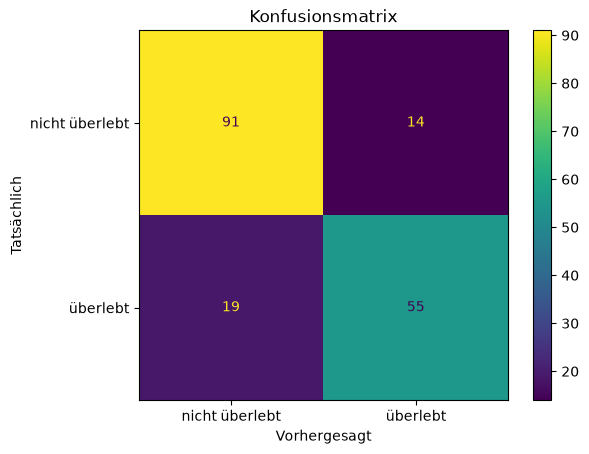

In [121]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy}")
graph_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, predictions,labels=model.classes_),
                                   display_labels=["nicht überlebt", "überlebt"])

graph_cm.plot()
graph_cm.ax_.set_xlabel("Vorhergesagt")
graph_cm.ax_.set_ylabel("Tatsächlich")
graph_cm.ax_.set_title("Konfusionsmatrix");


In [122]:
train_data['Title'] = train_data['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()

In [123]:
train_data['Title'].value_counts()


Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [124]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Title
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0,Mr


In [125]:
testdurchlauf = train_data.copy()
häufig_Titel = ['Mr','Miss','Mrs','Master']
testdurchlauf['Title'] = testdurchlauf['Title'].where(testdurchlauf['Title'].isin(häufig_Titel), 'NoName')
testdurchlauf = pd.get_dummies(testdurchlauf,columns=['Title'], dtype=int)

In [126]:
testdurchlauf.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_NoName
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0,0,0,1,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1,0,0,0,1,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0,0,0,0,1,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0,0,0,1,0,0


In [127]:
testdurchlauf['Ticket'].value_counts()

Ticket
347082             7
1601               7
CA. 2343           7
3101295            6
CA 2144            6
                  ..
SOTON/OQ 392076    1
211536             1
112053             1
111369             1
370376             1
Name: count, Length: 681, dtype: int64

In [128]:
ticket_anzahl = testdurchlauf['Ticket'].value_counts()
ticket_anzahl.head()


Ticket
347082      7
1601        7
CA. 2343    7
3101295     6
CA 2144     6
Name: count, dtype: int64

In [129]:
häufig_Ticket = ticket_anzahl[ticket_anzahl > 1].index
testdurchlauf['Ticket'] = testdurchlauf['Ticket'].where(testdurchlauf['Ticket'].isin(häufig_Ticket), 'NoZsm')
testdurchlauf = pd.get_dummies(testdurchlauf, columns=['Ticket'], dtype=int)
testdurchlauf.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,...,Ticket_PC 17761,Ticket_PP 9549,Ticket_S.C./PARIS 2079,Ticket_S.O./P.P. 3,Ticket_S.O.C. 14879,Ticket_SC/Paris 2123,Ticket_STON/O2. 3101279,Ticket_W./C. 6607,Ticket_W./C. 6608,Ticket_WE/P 5735
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,7.2500,0,...,0,0,0,0,0,0,0,0,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,71.2833,1,...,0,0,0,0,0,0,0,0,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,7.9250,0,...,0,0,0,0,0,0,0,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,53.1000,0,...,0,0,0,0,0,0,0,0,0,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,8.0500,0,...,0,0,0,0,0,0,0,0,0,0


In [130]:
testdurchlauf = testdurchlauf.drop(columns=["Name", "PassengerId"],)

In [131]:
testdurchlauf.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Columns: 148 entries, Survived to Ticket_WE/P 5735
dtypes: float64(2), int64(146)
memory usage: 1.0 MB


Accuracy: 0.8268156424581006
[[88 17]
 [14 60]]


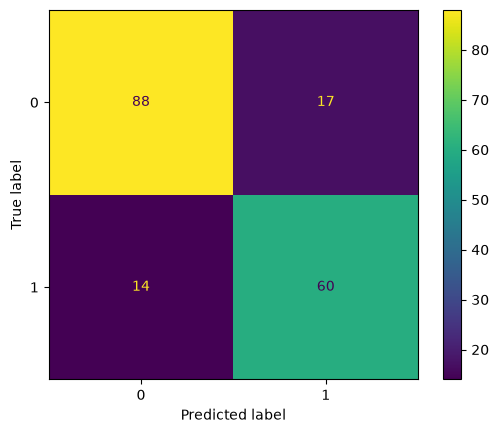

In [132]:
Xerweitert = testdurchlauf.drop('Survived', axis=1)
yerweitert = testdurchlauf['Survived']

Xerweitert_train, Xerweitert_test, yerweitert_train, yerweitert_test = train_test_split(Xerweitert, yerweitert, test_size=0.2, random_state=42)

modelerweitert = RandomForestClassifier(n_estimators=400, random_state=42)

modelerweitert.fit(Xerweitert_train, yerweitert_train)
predictionerweitert = modelerweitert.predict(Xerweitert_test)

accuracyerweitert = accuracy_score(y_test, predictionerweitert)
print(f"Accuracy: {accuracyerweitert}")

print(confusion_matrix(yerweitert_test, predictionerweitert))

ConfusionMatrixDisplay.from_predictions(yerweitert_test, predictionerweitert)

In [133]:
testdurchlauf['Cabin'] = train_data_original['Cabin'].fillna('NoCabin')
testdurchlauf['Cabin'].value_counts()

Cabin
NoCabin        687
G6               4
C23 C25 C27      4
B96 B98          4
F33              3
              ... 
E17              1
A24              1
C50              1
B42              1
C148             1
Name: count, Length: 148, dtype: int64

In [134]:
testdurchlauf['Cabin'] = testdurchlauf['Cabin'].str[0]
testdurchlauf['Cabin'].value_counts()

Cabin
N    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64

In [135]:
testdurchlauf = pd.get_dummies(testdurchlauf, columns=['Cabin'], dtype=int)
testdurchlauf.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title_Master,Title_Miss,...,Ticket_WE/P 5735,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_N,Cabin_T
0,0,3,0,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,1,1,1,38.0,1,0,71.2833,1,0,0,...,0,0,0,1,0,0,0,0,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,1,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,3,0,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,1,0


Accuracy: 0.8100558659217877
[[87 18]
 [16 58]]


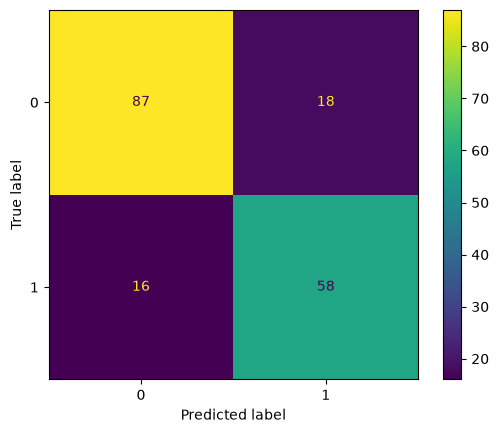

In [136]:
Xerweitert = testdurchlauf.drop('Survived', axis=1)
yerweitert = testdurchlauf['Survived']

Xerweitert_train, Xerweitert_test, yerweitert_train, yerweitert_test = train_test_split(Xerweitert, yerweitert, test_size=0.2, random_state=42)

modelerweitert = RandomForestClassifier(n_estimators=400, random_state=42)

modelerweitert.fit(Xerweitert_train, yerweitert_train)
predictionerweitert = modelerweitert.predict(Xerweitert_test)

accuracyerweitert = accuracy_score(y_test, predictionerweitert)
print(f"Accuracy: {accuracyerweitert}")

print(confusion_matrix(yerweitert_test, predictionerweitert))

ConfusionMatrixDisplay.from_predictions(yerweitert_test, predictionerweitert)

In [137]:
spalten_löschen = []
for spalte in testdurchlauf.columns:
    if spalte.startswith('Cabin_'):
        spalten_löschen.append(spalte)

testdurchlauf = testdurchlauf.drop(columns=spalten_löschen)

testdurchlauf['Cabin'] = train_data_original['Cabin']
testdurchlauf['Cabin'] = testdurchlauf['Cabin'].notna().astype(int)
testdurchlauf.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title_Master,Title_Miss,...,Ticket_PP 9549,Ticket_S.C./PARIS 2079,Ticket_S.O./P.P. 3,Ticket_S.O.C. 14879,Ticket_SC/Paris 2123,Ticket_STON/O2. 3101279,Ticket_W./C. 6607,Ticket_W./C. 6608,Ticket_WE/P 5735,Cabin
0,0,3,0,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,38.0,1,0,71.2833,1,0,0,...,0,0,0,0,0,0,0,0,0,1
2,1,3,1,26.0,0,0,7.9250,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Accuracy: 0.8379888268156425
[[91 14]
 [15 59]]


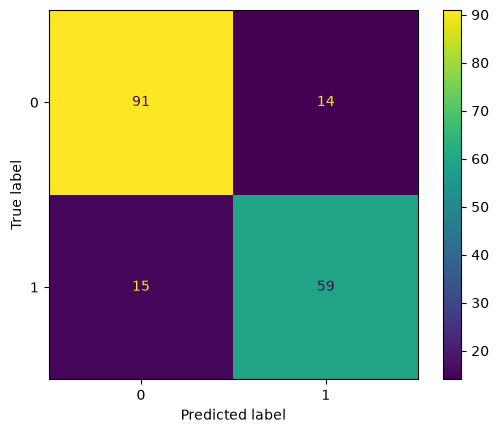

In [138]:
Xerweitert = testdurchlauf.drop('Survived', axis=1)
yerweitert = testdurchlauf['Survived']

Xerweitert_train, Xerweitert_test, yerweitert_train, yerweitert_test = train_test_split(Xerweitert, yerweitert, test_size=0.2, random_state=42)

modelerweitert = RandomForestClassifier(n_estimators=400, random_state=42)

modelerweitert.fit(Xerweitert_train, yerweitert_train)
predictionerweitert = modelerweitert.predict(Xerweitert_test)

accuracyerweitert = accuracy_score(yerweitert_test, predictionerweitert)
print(f"Accuracy: {accuracyerweitert}")

print(confusion_matrix(yerweitert_test, predictionerweitert))

ConfusionMatrixDisplay.from_predictions(yerweitert_test, predictionerweitert)

In [139]:
from sklearn.model_selection import cross_val_score
modelerweitert = RandomForestClassifier(n_estimators=400, random_state=42)
def cross_validation(model, X, y, cv=10):
    cross_val_scores = cross_val_score(model, X, y, cv=10)
    print(f"Kreuzvalidierungsergebnisse: {cross_val_scores}")
    print(f"Mittelwert der Kreuzvalidierung: {cross_val_scores.mean():.3f}")
    print(f"Standardabweichung: {cross_val_scores.std():.3f}")
    print(f"Finale Genauigkeit:{cross_val_scores.mean():.3f} ± {cross_val_scores.std():.3f}")
cross_validation(modelerweitert, Xerweitert, yerweitert, cv=10)


Kreuzvalidierungsergebnisse: [0.8        0.86516854 0.75280899 0.82022472 0.83146067 0.87640449
 0.79775281 0.76404494 0.88764045 0.85393258]
Mittelwert der Kreuzvalidierung: 0.825
Standardabweichung: 0.044
Finale Genauigkeit:0.825 ± 0.044


In [140]:
#from sklearn.linear_model import LogisticRegression
#model_logistic = LogisticRegression(random_state=42)
#cross_validation(model_logistic, Xerweitert, yerweitert, cv=10)
#Warnung: Die Schätzung kann nicht konvergieren.

In [141]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
model_logistic_pipeline = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
#model_logistic = LogisticRegression(random_state=42)
#cross_validation(model_logistic, Xerweitert, yerweitert, cv=10)

In [142]:
cross_validation(model_logistic_pipeline, Xerweitert, yerweitert, cv=10)

Kreuzvalidierungsergebnisse: [0.82222222 0.78651685 0.76404494 0.75280899 0.76404494 0.82022472
 0.74157303 0.82022472 0.85393258 0.85393258]
Mittelwert der Kreuzvalidierung: 0.798
Standardabweichung: 0.039
Finale Genauigkeit:0.798 ± 0.039


In [143]:
from sklearn.neighbors import KNeighborsClassifier
model_pipeline_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
cross_validation(model_pipeline_knn, Xerweitert, yerweitert, cv=10)

Kreuzvalidierungsergebnisse: [0.85555556 0.79775281 0.74157303 0.78651685 0.87640449 0.83146067
 0.80898876 0.80898876 0.84269663 0.79775281]
Mittelwert der Kreuzvalidierung: 0.815
Standardabweichung: 0.037
Finale Genauigkeit:0.815 ± 0.037


In [144]:
from sklearn.ensemble import GradientBoostingClassifier
model_pipeline_gb = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=100, random_state=42))
cross_validation(model_pipeline_gb, Xerweitert, yerweitert, cv=10)

Kreuzvalidierungsergebnisse: [0.83333333 0.84269663 0.75280899 0.84269663 0.87640449 0.80898876
 0.83146067 0.79775281 0.88764045 0.85393258]
Mittelwert der Kreuzvalidierung: 0.833
Standardabweichung: 0.037
Finale Genauigkeit:0.833 ± 0.037


In [145]:
model_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
cross_validation(model_gb, Xerweitert, yerweitert, cv=10)

Kreuzvalidierungsergebnisse: [0.83333333 0.84269663 0.75280899 0.84269663 0.87640449 0.80898876
 0.83146067 0.79775281 0.88764045 0.85393258]
Mittelwert der Kreuzvalidierung: 0.833
Standardabweichung: 0.037
Finale Genauigkeit:0.833 ± 0.037


In [146]:
def cross_validation(model, X, y, cv=10):
    cross_val_scores = cross_val_score(model, X, y, cv=10)
    return cross_val_scores.mean(), cross_val_scores.std(), cross_val_scores

compare = {"RandomForestClassifier": cross_validation(modelerweitert, Xerweitert, yerweitert, cv=10),
           "LogisticRegression": cross_validation(model_logistic_pipeline, Xerweitert, yerweitert, cv=10),
           "KNeighborsClassifier": cross_validation(model_pipeline_knn, Xerweitert, yerweitert, cv=10),
           "GradientBoostingClassifier": cross_validation(model_gb, Xerweitert, yerweitert, cv=10)}


     

In [147]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [148]:
model_tabelle = (pd.DataFrame(compare)
                 .iloc[[0, 1]]
                 .T
                 .set_axis(['Mittelwert', 'Standardabweichung'], axis=1)
                 .astype(float)
                 .sort_values(by='Mittelwert', ascending=False))
model_tabelle_style = model_tabelle.style.set_table_styles([{'selector': 'th.row_heading', 'props': [('text-align', 'left')]}]).format(precision=3)
model_tabelle_style

,Mittelwert,Standardabweichung
GradientBoostingClassifier,0.833,0.037
RandomForestClassifier,0.825,0.044
KNeighborsClassifier,0.815,0.037
LogisticRegression,0.798,0.039


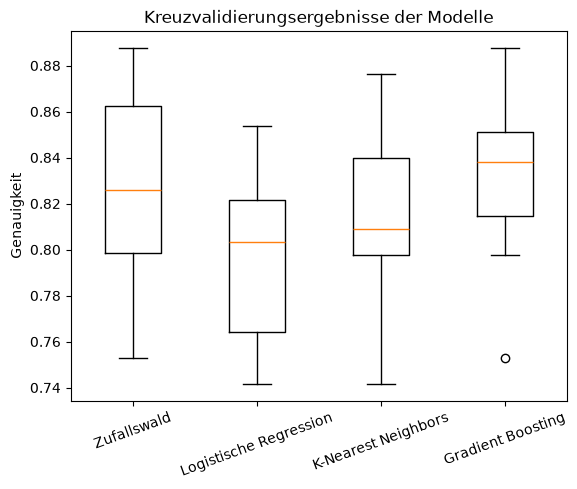

In [149]:
import matplotlib.pyplot as plt

model_name = compare.keys()
model_wert = []
for wert in compare.values():
    model_wert.append(wert[2])
    
plt.boxplot(model_wert, tick_labels=["Zufallswald", "Logistische Regression", "K-Nearest Neighbors", "Gradient Boosting"])
plt.title("Kreuzvalidierungsergebnisse der Modelle")
plt.ylabel("Genauigkeit")
plt.xticks(rotation=20)
plt.show()

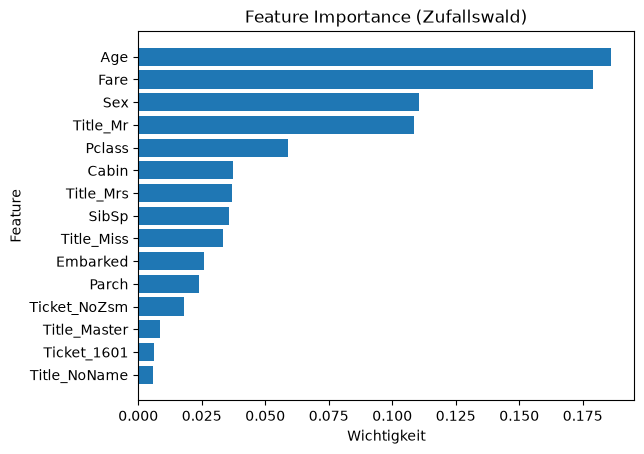

In [150]:
modelerweitert.fit(Xerweitert, yerweitert)
werte = modelerweitert.feature_importances_
feature = pd.Series(werte, index=Xerweitert.columns)
top = feature.nlargest(15)
top.sort_values(inplace=True)
#plt.barh(feature.index, feature.values) #Für alle Features, nicht nur die Top 15
plt.barh(top.index, top.values)
plt.title("Feature Importance (Zufallswald)")
plt.xlabel("Wichtigkeit")
plt.ylabel("Feature")
plt.show()

In [151]:
#Ticket löschen da, die fast kein Einfluss auf feature haben, um zu schauen ob das model ohne ticket genauso gut abschneidet
spalten_löschen = []
for spalte in testdurchlauf.columns:
    if spalte.startswith('Ticket_'):
        spalten_löschen.append(spalte)

testdurchlauf = testdurchlauf.drop(columns=spalten_löschen)

Xerweitert = testdurchlauf.drop('Survived', axis=1)
yerweitert = testdurchlauf['Survived']
model_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
cross_validation(model_gb, Xerweitert, yerweitert, cv=10)
print(f"Finale Genauigkeit GradientBoostingClassifier: {cross_validation(model_gb, Xerweitert, yerweitert, cv=10)[0]:.3f} ± {cross_validation(model_gb, Xerweitert, yerweitert, cv=10)[1]:.3f}")


Finale Genauigkeit GradientBoostingClassifier: 0.831 ± 0.045


In [152]:
compare = {"RandomForestClassifier": cross_validation(modelerweitert, Xerweitert, yerweitert, cv=10),
           "LogisticRegression": cross_validation(model_logistic_pipeline, Xerweitert, yerweitert, cv=10),
           "KNeighborsClassifier": cross_validation(model_pipeline_knn, Xerweitert, yerweitert, cv=10),
           "GradientBoostingClassifier": cross_validation(model_gb, Xerweitert, yerweitert, cv=10)}

In [153]:

from sklearn.model_selection import GridSearchCV
param_grid = {
    "n_estimators": [100, 200, 400],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2,3,5]
    }
grid = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=10, scoring="accuracy", n_jobs=-1)
grid.fit(Xerweitert, yerweitert)
print(grid.best_params_)
print(grid.best_score_)


{'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 400}
0.8462546816479402


In [154]:
param_grid = {
    "n_estimators": [300, 400, 500],
    "learning_rate": [0.005, 0.01, 0.02],
    "max_depth": [4, 5, 6]
    }
grid = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=10, scoring="accuracy", n_jobs=-1)
grid.fit(Xerweitert, yerweitert)
print(grid.best_params_)
print(grid.best_score_)

{'learning_rate': 0.02, 'max_depth': 5, 'n_estimators': 500}
0.8462796504369537


In [155]:
model_gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.02, max_depth=5, random_state=42)
cross_validation(model_gb, Xerweitert, yerweitert, cv=10)
print(f"Finale Genauigkeit GradientBoostingClassifier: {cross_validation(model_gb, Xerweitert, yerweitert, cv=10)[0]:.3f} ± {cross_validation(model_gb, Xerweitert, yerweitert, cv=10)[1]:.3f}")


Finale Genauigkeit GradientBoostingClassifier: 0.846 ± 0.050


In [156]:
train_data_original["Fare"].value_counts()

Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64

In [157]:
#finale funktion für die abgabe bei kaggle
def vollständiges_model():
    train_data = pd.read_csv('train.csv')
    test_data = pd.read_csv('test.csv')
    def data_type(data):
        data = data.copy()
        data['Age'] = data['Age'].fillna(25)
        data['Embarked'] = data['Embarked'].fillna('S')
        data['Fare'] = data['Fare'].fillna(8.0500)
        data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
        data['Embarked'] = data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
        data['Title'] = data['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()
        häufig_Titel = ['Mr','Miss','Mrs','Master']
        data['Title'] = data['Title'].where(data['Title'].isin(häufig_Titel), 'NoName')
        data = pd.get_dummies(data,columns=['Title'], dtype=int)
        data['Cabin'] = data['Cabin'].notna().astype(int)
        data = data.drop(columns=["Name", "Ticket", "PassengerId"])
        return data
    model_gb = GradientBoostingClassifier(n_estimators=500, learning_rate=0.02, max_depth=5, random_state=42)
    X = data_type(train_data).drop('Survived', axis=1)
    X_test = data_type(test_data)
    X_test = X_test.reindex(columns=X.columns, fill_value=0)  #Jede Spalte wird exakt kopiert, falls eine Spalte in test_data nicht exsistiert
    y = train_data['Survived']
    model_gb.fit(X, y)
    prediction = model_gb.predict(X_test)
    output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': prediction})
    return output
vollständiges_model().to_csv('final_submission.csv', index=False)


In [158]:
final_check = pd.read_csv('test.csv')
def data_type(data):
        data = data.copy()
        data['Age'] = data['Age'].fillna(25)
        data['Embarked'] = data['Embarked'].fillna('S')
        data['Fare'] = data['Fare'].fillna(8.0500)
        data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
        data['Embarked'] = data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
        data['Title'] = data['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()
        häufig_Titel = ['Mr','Miss','Mrs','Master']
        data['Title'] = data['Title'].where(data['Title'].isin(häufig_Titel), 'NoName')
        data = pd.get_dummies(data,columns=['Title'], dtype=int)
        data['Cabin'] = data['Cabin'].notna().astype(int)
        data = data.drop(columns=["Name", "Ticket", "PassengerId"])
        return data
final_check_op = data_type(final_check)
print(final_check_op.shape)
print(final_check_op.isna().sum().sum())#checken ob Spalten fehlen



(418, 13)
0


In [159]:
final_sub_check = pd.read_csv('final_submission.csv')
print(final_sub_check.shape)
print(final_sub_check.head())
print(final_sub_check['Survived'].value_counts())

(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
Survived
0    269
1    149
Name: count, dtype: int64


In [165]:
#train_data = pd.read_csv('train.csv')
train_data["Survived"].groupby(train_data["Sex"]).value_counts(normalize=True).unstack()
train_data["Survived"].groupby(train_data["Pclass"]).value_counts(normalize=True).unstack()
display(train_data["Survived"].groupby(train_data["Sex"]).value_counts(normalize=True).unstack())
display(train_data["Survived"].groupby(train_data["Pclass"]).value_counts(normalize=True).unstack())

Survived,0,1
Sex,,
0,0.811092,0.188908
1,0.257962,0.742038


Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363
